# Puzzle World - Tahap 1: Puzzle Generator
Input: 1 gambar (RGB / grayscale) + parameter `M` (grid M x M).  
Bingkai = **gambar asli itu sendiri** dengan bagian tengahnya dikosongkan (berkontur grid). Potongan puzzle diambil dari bagian tengah yang dikosongkan itu, jadi ukurannya pas dengan lubang bingkai.  
Output: 1 berkas bingkai + N = M x M berkas potongan (di-shuffle dan di-rotate) + `info.json` sebagai kunci jawaban.

## 1. Setup dan parameter

In [82]:
import io
import json
import math
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ---- Parameter (ubah di sini) ----
IMAGE_SOURCE = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRfukVlyVmsM27gQbW-YfHLOSw740iO84r7NJLKb6RCgRxqYiChrwTlxKk-&s=10"   # URL gambar, atau path file lokal (mis. "gambar.png")
M = 3                                      # jumlah potongan per sisi -> N = M x M
FRAME_BORDER = 0.12                        # tebal minimal bingkai, sebagai pecahan dari sisi terpendek gambar
OUT_DIR = "puzzle_output"                  # folder tempat berkas output disimpan
SHUFFLE = True                             # acak urutan potongan (nama berkas tidak membocorkan posisi)
ROTATE = True                              # putar acak tiap potongan: 0 / 90 / 180 / 270 derajat
SEED = None                               # supaya hasil acak bisa diulang

## 2. Membaca citra

In [83]:
def load_image(source):
    """Baca gambar dari URL atau path lokal.
    Hasil: array uint8 (H, W) untuk grayscale atau (H, W, 3) untuk RGB."""
    if source.startswith(("http://", "https://")):
        req = urllib.request.Request(source, headers={"User-Agent": "Mozilla/5.0"})
        data = urllib.request.urlopen(req, timeout=15).read()
        im = Image.open(io.BytesIO(data))
    else:
        im = Image.open(source)

    # Pertahankan grayscale bila memang grayscale; selain itu jadikan RGB (juga membuang alpha/palette)
    im = im.convert("L") if im.mode in ("L", "1", "I", "I;16", "F") else im.convert("RGB")
    return np.array(im, dtype=np.uint8)

## 3. Menentukan lubang bingkai (area potongan)

In [84]:
def compute_hole(H, W, M, border_frac=0.12):
    """Tentukan area persegi di tengah gambar yang akan dikosongkan (lubang bingkai).
    Sisanya tetap berisi gambar asli dan menjadi bingkai. Tiap sel berbentuk persegi sisi s,
    sehingga potongan tetap pas di lubang walau diputar 90 derajat.
    Mengembalikan (top, left, s) dengan ukuran lubang = s*M."""
    b = max(2, int(round(border_frac * min(H, W))))   # tebal minimal bingkai
    s = min(H - 2 * b, W - 2 * b) // M                # sisi satu sel/potongan
    if s < 4:
        raise ValueError(f"M={M} terlalu besar untuk gambar {W}x{H}. Kecilkan M atau FRAME_BORDER.")
    L = s * M
    return (H - L) // 2, (W - L) // 2, s

## 4. Membuat bingkai (frame)

In [85]:
def make_frame(img, top, left, s, M, thickness=2, bg=235, line=40):
    """Bingkai = gambar asli dengan area lubang dikosongkan (abu terang), lalu digambari
    garis grid M x M dan kontur lubang sebagai acuan penyusunan. Ukuran/rasio sama dengan gambar."""
    L = s * M
    frame = img.copy()
    frame[top:top + L, left:left + L] = bg            # kosongkan lubang (berlaku untuk RGB maupun grayscale)

    # Garis grid antar sel
    for i in range(1, M):
        y, x = top + i * s, left + i * s
        frame[y - thickness // 2: y + (thickness + 1) // 2, left:left + L] = line
        frame[top:top + L, x - thickness // 2: x + (thickness + 1) // 2] = line

    # Kontur lubang (sedikit lebih tebal, digambar di sisi dalam lubang)
    t = thickness + 1
    frame[top:top + t, left:left + L] = line
    frame[top + L - t:top + L, left:left + L] = line
    frame[top:top + L, left:left + t] = line
    frame[top:top + L, left + L - t:left + L] = line
    return frame

## 5. Memotong gambar menjadi N potongan

In [86]:
def split_into_pieces(img, top, left, s, M):
    """Potong area lubang menjadi M x M potongan persegi (sisi s), urutan baris demi baris.
    Mengembalikan list of (potongan, baris, kolom)."""
    pieces = []
    for r in range(M):
        for c in range(M):
            y, x = top + r * s, left + c * s
            pieces.append((img[y:y + s, x:x + s].copy(), r, c))
    return pieces

## 6. Shuffle dan rotasi acak

In [87]:
def rotate90(img, k):
    """Putar k x 90 derajat berlawanan arah jarum jam: transpose lalu flip baris."""
    for _ in range(k % 4):
        img = img.swapaxes(0, 1)[::-1]
    return img


def randomize_pieces(pieces, shuffle=True, rotate=True, seed=None):
    """Acak urutan potongan dan/atau putar tiap potongan secara acak (0/90/180/270 derajat).
    Mengembalikan list of dict: piece, row, col (posisi asli), rot (jumlah putaran 90 derajat
    berlawanan arah jarum jam; untuk mengembalikan: rotate90(piece, -rot))."""
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(pieces)) if shuffle else np.arange(len(pieces))

    result = []
    for idx in order:
        piece, r, c = pieces[idx]
        rot = int(rng.integers(0, 4)) if rotate else 0
        result.append({"piece": rotate90(piece, rot).copy(), "row": r, "col": c, "rot": rot})
    return result

## 7. Menyimpan output

In [88]:
def save_puzzle(frame, items, out_dir, M, hole):
    """Simpan 1 bingkai (frame.png), N potongan (piece_000.png, ...) dan info.json.
    PNG dipakai agar tanpa kehilangan kualitas. info.json = kunci jawaban untuk evaluasi solver
    (solver sendiri tidak boleh membacanya)."""
    top, left, s = hole
    os.makedirs(out_dir, exist_ok=True)
    Image.fromarray(frame).save(os.path.join(out_dir, "frame.png"))

    info = {"M": M, "N": M * M,
            "frame_height": frame.shape[0], "frame_width": frame.shape[1],
            "hole": {"top": top, "left": left, "cell_size": s, "size": s * M},
            "pieces": []}
    for i, it in enumerate(items):
        name = f"piece_{i:03d}.png"
        Image.fromarray(it["piece"]).save(os.path.join(out_dir, name))
        info["pieces"].append({"file": name, "row": it["row"], "col": it["col"], "rotation": it["rot"]})

    with open(os.path.join(out_dir, "info.json"), "w") as f:
        json.dump(info, f, indent=2)
    return info

## 8. Fungsi utama: Puzzle Generator

In [89]:
def generate_puzzle(img, M, out_dir="puzzle_output", border_frac=0.12, shuffle=True, rotate=True, seed=None):
    """Puzzle Generator: gambar + M -> 1 bingkai + N = M x M potongan.
    Mengembalikan (bingkai, list potongan, info, hole)."""
    H, W = img.shape[:2]
    top, left, s = compute_hole(H, W, M, border_frac)       # 1. tentukan lubang bingkai
    frame = make_frame(img, top, left, s, M)                # 2. bingkai dari gambar asli + lubang berkontur
    pieces = split_into_pieces(img, top, left, s, M)        # 3. potong lubang menjadi N potongan
    items = randomize_pieces(pieces, shuffle, rotate, seed) # 4. shuffle + rotasi acak
    info = save_puzzle(frame, items, out_dir, M, (top, left, s))
    return frame, items, info, (top, left, s)

## 9. Demo dan verifikasi

Gambar masukan: (447, 447, 3) | tipe: uint8
Ukuran bingkai : (447, 447, 3) (sama dengan gambar)
Lubang bingkai : 339 x 339 px, di posisi (y, x) = (54, 54)
Jumlah potongan: 9 | ukuran tiap potongan: (113, 113, 3)
Rotasi tiap potongan (x90 derajat): [3, 0, 2, 0, 1, 3, 3, 2, 0]
Berkas di puzzle_output : 18 berkas (1 bingkai + N potongan + info.json)
Verifikasi OK: bingkai + potongan identik dengan gambar asli.


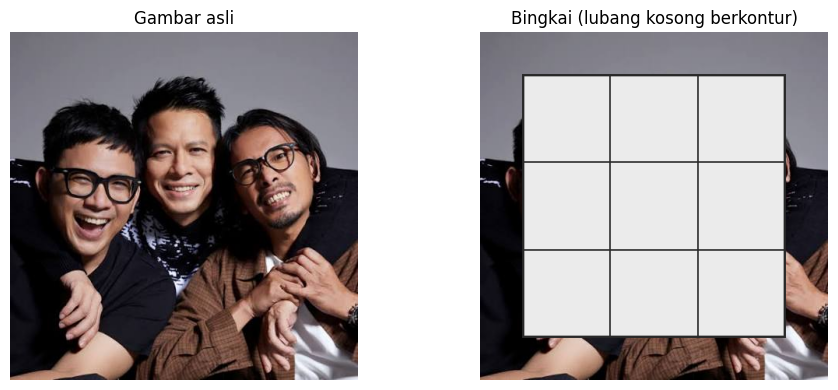

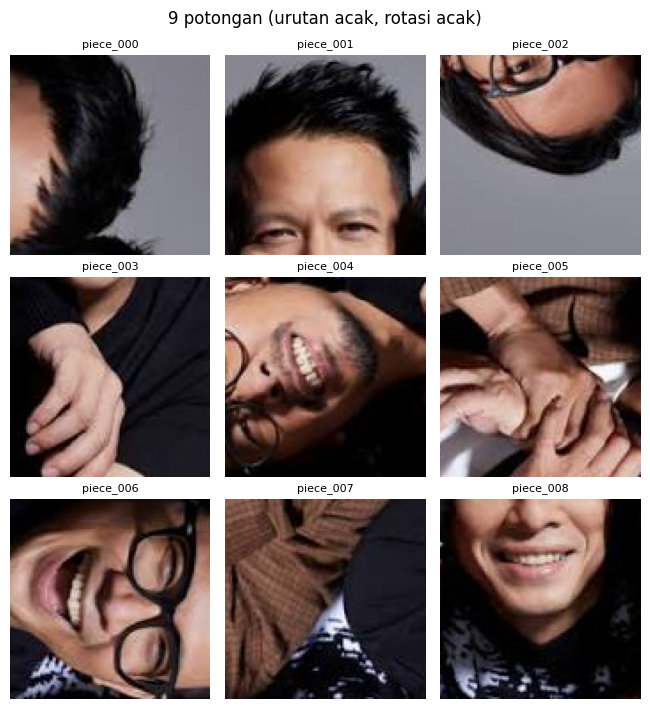

In [90]:
img = load_image(IMAGE_SOURCE)
print("Gambar masukan:", img.shape, "| tipe:", img.dtype)

frame, items, info, (top, left, s) = generate_puzzle(img, M, OUT_DIR, FRAME_BORDER, SHUFFLE, ROTATE, SEED)

print("Ukuran bingkai :", frame.shape, "(sama dengan gambar)")
print("Lubang bingkai :", s * M, "x", s * M, "px, di posisi (y, x) =", (top, left))
print("Jumlah potongan:", len(items), "| ukuran tiap potongan:", items[0]["piece"].shape)
print("Rotasi tiap potongan (x90 derajat):", [it["rot"] for it in items])
print("Berkas di", OUT_DIR, ":", len(os.listdir(OUT_DIR)), "berkas (1 bingkai + N potongan + info.json)")

# ---- Verifikasi: tempel potongan (setelah rotasi dibatalkan) ke bingkai, harus sama dengan gambar asli ----
with open(os.path.join(OUT_DIR, "info.json")) as f:
    meta = json.load(f)
h = meta["hole"]
rebuilt = np.array(Image.open(os.path.join(OUT_DIR, "frame.png")))
for p in meta["pieces"]:
    piece = rotate90(np.array(Image.open(os.path.join(OUT_DIR, p["file"]))), -p["rotation"])
    y, x = h["top"] + p["row"] * h["cell_size"], h["left"] + p["col"] * h["cell_size"]
    rebuilt[y:y + h["cell_size"], x:x + h["cell_size"]] = piece

assert meta["N"] == M * M == len(meta["pieces"])
assert frame.shape == img.shape                       # bingkai meniru ukuran gambar
assert all(it["piece"].shape[:2] == (s, s) for it in items)   # semua potongan pas dengan sel bingkai
assert np.array_equal(rebuilt, img)                   # bingkai + potongan = gambar asli, tanpa piksel hilang
print("Verifikasi OK: bingkai + potongan identik dengan gambar asli.")

# ---- Tampilan ----
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=255)
plt.title("Gambar asli")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(frame, cmap="gray" if frame.ndim == 2 else None, vmin=0, vmax=255)
plt.title("Bingkai (lubang kosong berkontur)")
plt.axis("off")
plt.tight_layout()
plt.show()

cols = M
rows = math.ceil(len(items) / cols)
plt.figure(figsize=(2.2 * cols, 2.4 * rows))
for i, it in enumerate(items):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(it["piece"], cmap="gray" if it["piece"].ndim == 2 else None, vmin=0, vmax=255)
    plt.title(f"piece_{i:03d}", fontsize=8)
    plt.axis("off")
plt.suptitle(f"{len(items)} potongan (urutan acak, rotasi acak)")
plt.tight_layout()
plt.show()